# Sherlock Holmes: como localizar informações em nove obras?

Este notebook compara busca literal e TF-IDF: cada consulta pode retornar até cinco parágrafos, com arquivo e linhas de origem para conferência.

A análise pergunta se cada método encontra uma referência conhecida e o que retorna quando a consulta não tem resposta. As obras servem como exemplo de busca documental; os resultados não medem o desempenho em documentos de clientes.

O percurso é conhecer o acervo, entender os métodos, comparar os resultados e examinar os erros.

*English summary:* This analysis compares literal and TF-IDF retrieval over nine Sherlock Holmes works. It shows corpus size, known-reference hits among the top five results, and returns for unanswerable queries. The small, curated benchmark is not an exhaustive relevance assessment.

## 1. Preparar a análise no Kaggle

1. Anexe o dataset [Sherlock Holmes Series](https://www.kaggle.com/datasets/talesgomes27/sherleck-books).
2. Habilite **Internet** para instalar as ferramentas e preparar o ambiente Python.
3. Execute as células na ordem.

Todo o código necessário está neste notebook. Não é preciso criar outra conta nem clonar um projeto. O processamento usa um ambiente Python separado, sem substituir as bibliotecas do kernel. Os arquivos do dataset são somente lidos; os resultados ficam em `/kaggle/working/sherlock_analysis`.

In [1]:
import base64
import hashlib
import io
import json
import os
from pathlib import Path
import subprocess
import sys
import zipfile
from IPython.display import display, Markdown

WORK_DIR = Path(os.environ.get("SHERLOCK_NOTEBOOK_WORK_DIR", "/kaggle/working/sherlock_analysis")).expanduser().resolve()
local_raw = os.environ.get("SHERLOCK_RAW_DIR")
if local_raw:
    RAW_DIR = Path(local_raw).expanduser().resolve()
else:
    candidates = list(Path("/kaggle/input").rglob("a_study_in_scarlet.txt"))
    if len(candidates) != 1:
        raise RuntimeError("Anexe uma única cópia do dataset Sherlock Holmes Series antes de executar.")
    RAW_DIR = candidates[0].parent.resolve()
if WORK_DIR.is_relative_to(RAW_DIR):
    raise ValueError("As saídas devem ficar fora do dataset de entrada.")
WORK_DIR.mkdir(parents=True, exist_ok=True)
SOURCE_DIR = WORK_DIR / "analysis"
REPORT_PATH = WORK_DIR / "search_results.json"

def run_quiet(command, *, cwd=None, env=None):
    result = subprocess.run(command, cwd=cwd, env=env, text=True, capture_output=True)
    if result.returncode:
        details = (result.stdout + "\n" + result.stderr).replace(str(WORK_DIR), "<workspace>").replace(str(RAW_DIR), "<dataset>")
        details = details.replace(str(Path.home()), "<home>")
        raise RuntimeError(f"Falha ao preparar ou executar a análise:\n{details[-5000:]}")
    return result

print("Dataset localizado. As próximas células preparam o ambiente e calculam os resultados.")


Dataset localizado. As próximas células preparam o ambiente e calculam os resultados.


In [2]:
BUNDLE_B64 = "..."
BUNDLE_SHA256 = "78f7cea8770d3458daa30d7a2a7cd4ed36a55e2216e1ce7f4ff76600292004ca"
# END EMBEDDED PAYLOAD

payload = base64.b64decode(BUNDLE_B64, validate=True)
if hashlib.sha256(payload).hexdigest() != BUNDLE_SHA256:
    raise ValueError("Código incluído no notebook está incompleto ou foi alterado.")
if SOURCE_DIR.is_symlink():
    raise ValueError("Use uma pasta de saída sem links simbólicos.")
SOURCE_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(io.BytesIO(payload)) as archive:
    for member in archive.infolist():
        target = (SOURCE_DIR / member.filename).resolve()
        if not target.is_relative_to(SOURCE_DIR.resolve()) or member.is_dir():
            raise ValueError("Caminho inválido no código incluído.")
        content = archive.read(member)
        if target.exists():
            if target.read_bytes() != content:
                raise ValueError("Código existente diverge desta análise; use uma nova pasta de saída.")
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(content)
print("Código da análise disponível localmente.")


Código da análise disponível localmente.


In [3]:
UV_VERSION = "0.13.5"
probe = subprocess.run([sys.executable, "-m", "uv", "--version"], text=True, capture_output=True)
if probe.returncode or probe.stdout.strip().split()[1:2] != [UV_VERSION]:
    run_quiet([sys.executable, "-m", "pip", "install", f"uv=={UV_VERSION}"])
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    run_quiet([sys.executable, "-m", "pip", "install", "matplotlib==3.11.2"])
    import matplotlib.pyplot as plt

UV_ENV = os.environ.copy()
UV_ENV.pop("VIRTUAL_ENV", None)
UV_ENV.pop("UV_PROJECT_ENVIRONMENT", None)
UV_ENV["UV_CACHE_DIR"] = str(WORK_DIR / "cache")
UV_ENV["UV_PYTHON_INSTALL_DIR"] = str(WORK_DIR / "python")
run_quiet([sys.executable, "-m", "uv", "sync", "--managed-python", "--python", "3.11.17", "--frozen"],
          cwd=SOURCE_DIR, env=UV_ENV)
run_quiet([sys.executable, "-m", "uv", "run", "--managed-python", "--python", "3.11.17", "--frozen",
           "python", "-m", "sherlock_search.final_evaluation", "--root", str(SOURCE_DIR),
           "--raw-dir", str(RAW_DIR), "--output", str(REPORT_PATH)], cwd=SOURCE_DIR, env=UV_ENV)
report = json.loads(REPORT_PATH.read_text(encoding="utf-8"))
assert report["query_count"] == 20 and len(report["results"]) == 20
assert report["corpus"]["totals"]["files"] == 9
print("Análise calculada: 9 obras e 20 consultas. Veja os resultados abaixo.")


Análise calculada: 9 obras e 20 consultas. Veja os resultados abaixo.


## 2. Conhecer o acervo

Os nove arquivos, em inglês, reúnem romances e coletâneas de Arthur Conan Doyle. A preparação lê arquivos UTF-8 com BOM, normaliza as quebras de linha em memória e aplica recortes editoriais revisados para retirar cabeçalhos e rodapés. Cada parágrafo mantém o nome do arquivo e suas linhas originais, numeradas a partir de 1.

A contagem considera sequências de letras Unicode e aceita apóstrofos ou hífens dentro das palavras. Números não entram na contagem. O gráfico mostra o volume de texto, não a qualidade dos livros nem o desempenho da busca em cada obra.

In [4]:
def number(value):
    return f"{value:,}".replace(",", ".")

def table(headers, rows):
    def escape(value):
        return str(value).replace("|", r"\|").replace("\n", " ")
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(escape(value) for value in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

totals = report["corpus"]["totals"]
display(Markdown(f"**{totals['files']} obras · {number(totals['retained_words'])} palavras retidas · "
                 f"{number(totals['paragraphs'])} parágrafos**\n\n"
                 f"Os recortes excluíram {number(totals['removed_words'])} palavras dos originais."))
books = sorted(report["corpus"]["files"], key=lambda book: book["retained_words"], reverse=True)
table(["Obra", "Palavras retidas", "Parágrafos"],
      [(book["title"], number(book["retained_words"]), number(book["paragraphs"])) for book in books])


**9 obras · 656.884 palavras retidas · 15.598 parágrafos**

Os recortes excluíram 29.566 palavras dos originais.

| Obra | Palavras retidas | Parágrafos |
| --- | --- | --- |
| The Return of Sherlock Holmes | 112.364 | 2.573 |
| The Adventures of Sherlock Holmes | 104.454 | 2.540 |
| The Memoirs of Sherlock Holmes | 95.549 | 2.191 |
| The Case-Book of Sherlock Holmes | 82.179 | 2.247 |
| The Hound of the Baskervilles | 59.225 | 1.483 |
| His Last Bow | 58.982 | 1.424 |
| The Valley of Fear | 57.690 | 1.551 |
| A Study in Scarlet | 43.334 | 805 |
| The Sign of the Four | 43.107 | 784 |

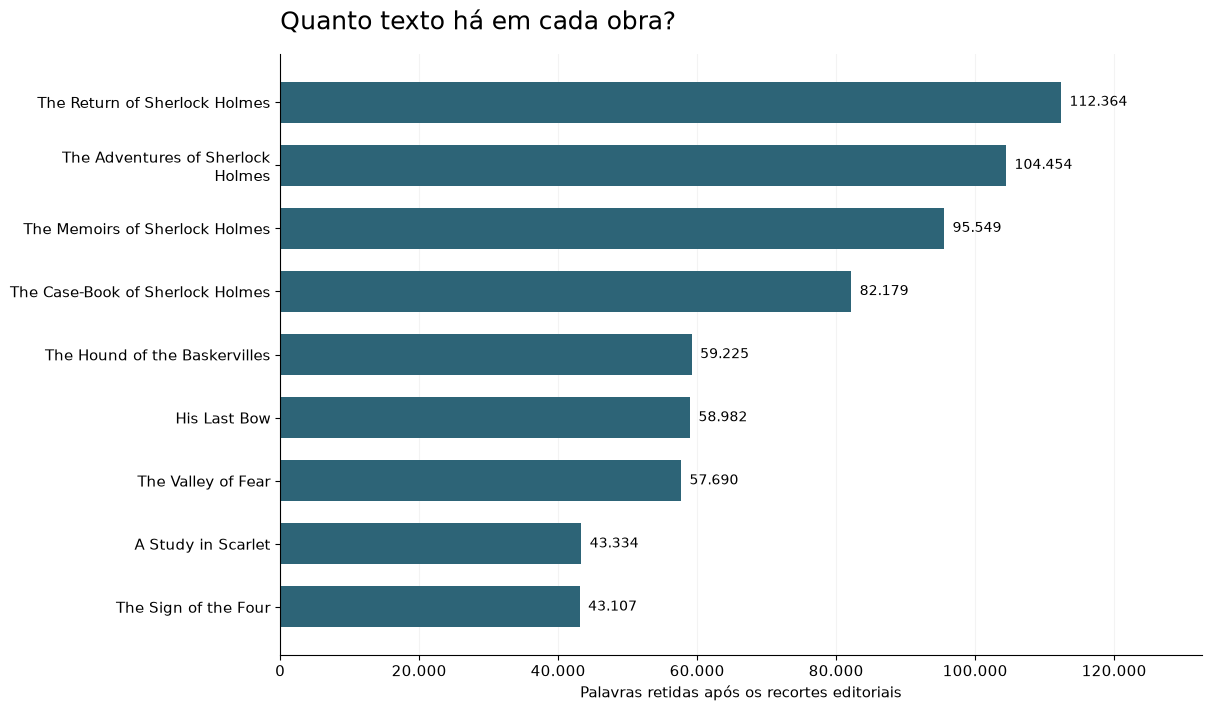

In [5]:
from textwrap import fill
from matplotlib.ticker import FuncFormatter, PercentFormatter

FIGURE_DIR = WORK_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def export_figure(fig, name):
    for extension in ("png", "svg"):
        fig.savefig(FIGURE_DIR / f"{name}.{extension}", dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 7), layout="constrained")
values = [book["retained_words"] for book in books]
bars = ax.barh([fill(book["title"], 32) for book in books], values, color="#2D6477", height=0.65)
ax.invert_yaxis()
ax.bar_label(bars, labels=[number(value) for value in values], padding=6, fontsize=10)
ax.set_xlim(0, max(values) * 1.18)
ax.set_xlabel("Palavras retidas após os recortes editoriais")
ax.set_title("Quanto texto há em cada obra?", loc="left", fontsize=18, pad=18)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: number(int(value))))
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
export_figure(fig, "corpus_size")


## 3. O que estamos comparando?

| Método | Como encontra parágrafos | Como os ordena |
|---|---|---|
| Literal | Procura o termo ou a expressão inteira, sem diferenciar maiúsculas e minúsculas. | Número de ocorrências; em caso de empate, ordem estável por arquivo e linhas. |
| TF-IDF | Representa consulta e parágrafos por pesos de palavras e remove palavras muito comuns em inglês. | Similaridade de cosseno; mostra somente scores acima de zero. |

TF-IDF dá mais peso a palavras que ajudam a distinguir um trecho. Ele compara palavras, sem interpretar o sentido como um modelo de linguagem. Seu score não é a probabilidade de a consulta ter resposta e não pode ser comparado à contagem de ocorrências da busca literal.

Dez consultas de desenvolvimento orientaram a configuração, que ficou definida antes da avaliação final. O teste final tem **20 consultas**: **16 com referências conhecidas** e **4 sem resposta**. Os métodos pesquisam todo o acervo, mas as respostas anotadas no teste final não foram usadas para definir os parâmetros.

- **Referência conhecida entre os cinco primeiros resultados (top 5):** conta quantas consultas com resposta conhecida têm pelo menos um parágrafo anotado entre os cinco retornados. Um número maior indica mais referências conhecidas encontradas nesse limite.
- **Consulta negativa com retorno:** conta quantas consultas sem resposta fazem o método devolver algum parágrafo. Um número menor significa menos retornos para essas consultas; não prova que o método reconhece toda pergunta sem resposta.

O corte do TF-IDF é 0,0, então scores iguais a zero são descartados. Esse corte foi escolhido durante o desenvolvimento e não foi ajustado depois de examinar as consultas finais.

| Método | Referência no top 5 (16 positivas) | Negativas com retorno (4 negativas) |
| --- | --- | --- |
| Literal | 7/16 (43.75%) | 0/4 (0%) |
| TF-IDF | 8/16 (50.00%) | 4/4 (100%) |

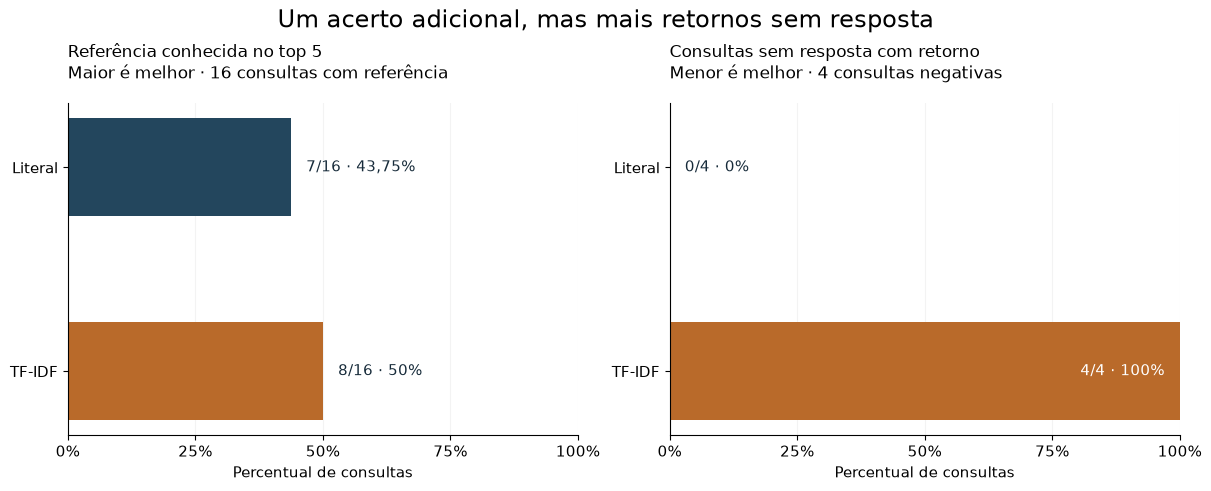

In [6]:
methods = [("literal", "Literal", "#23465D"), ("tfidf", "TF-IDF", "#B96A2A")]
table(["Método", "Referência no top 5 (16 positivas)", "Negativas com retorno (4 negativas)"],
      [(label, f"{report[key]['positive_hits']}/16 ({report[key]['known_hit_at_5']:.2%})",
        f"{report[key]['false_positive_queries']}/4 ({report[key]['false_positive_rate']:.0%})")
       for key, label, color in methods])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
panels = [("known_hit_at_5", "positive_hits", "positive_queries", "Referência conhecida no top 5", "Maior é melhor · 16 consultas com referência"),
          ("false_positive_rate", "false_positive_queries", "negative_queries", "Consultas sem resposta com retorno", "Menor é melhor · 4 consultas negativas")]
for ax, (metric, count, denominator, title, subtitle) in zip(axes, panels):
    rates = [report[key][metric] for key, label, color in methods]
    bars = ax.barh([label for key, label, color in methods], rates, color=[color for key, label, color in methods], height=0.48)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xticks([0, .25, .5, .75, 1])
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(title + "\n" + subtitle, loc="left", fontsize=12, pad=18)
    ax.set_xlabel("Percentual de consultas")
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
    for bar, (key, label, color), rate in zip(bars, methods, rates):
        text = f"{report[key][count]}/{report[key][denominator]} · {rate:.2%}".replace(".00%", "%").replace(".", ",")
        inside = rate >= 0.85
        ax.text(rate - 0.03 if inside else rate + 0.03, bar.get_y() + bar.get_height()/2, text,
                va="center", ha="right" if inside else "left", color="white" if inside else "#172B3A", fontsize=11)
fig.suptitle("Um acerto adicional, mas mais retornos sem resposta", fontsize=17)
export_figure(fig, "retrieval_comparison")


## 4. Examinar as consultas e os erros

Entre as **16 consultas positivas**, o TF-IDF encontrou uma referência conhecida no top 5 em **8**; a busca literal encontrou em **7**. Nas **4 consultas negativas**, o TF-IDF devolveu parágrafos em **4**, enquanto a busca literal não devolveu nenhum. Uma palavra em comum pode gerar similaridade mesmo quando o trecho não responde à pergunta. Esses resultados descrevem este teste e não demonstram que um método seja melhor em geral.

Na primeira tabela, **sim** quer dizer que pelo menos uma referência anotada apareceu entre os cinco primeiros resultados. **Não** quer dizer que essa referência conhecida não apareceu. Outros trechos ainda podem ser relevantes, pois as anotações não incluem necessariamente todos eles. A segunda tabela conta os parágrafos devolvidos para cada consulta sem resposta.

In [7]:
queries = json.loads((SOURCE_DIR / "evaluation/final.json").read_text(encoding="utf-8"))
query_text = {query["id"]: query["query"] for query in queries}
positive_rows, negative_rows = [], []
for item in report["results"]:
    if item["answerable"]:
        known = set(item["known_relevant_ids"])
        hits = ["sim" if any(row["id"] in known for row in item[key][:5]) else "não" for key, label, color in methods]
        positive_rows.append((item["id"], query_text[item["id"]], *hits))
    else:
        negative_rows.append((item["id"], query_text[item["id"]], len(item["literal"]), len(item["tfidf"])))
display(Markdown("### Consultas com referência conhecida"))
table(["ID", "Consulta original (inglês)", "Literal: referência no top 5?", "TF-IDF: referência no top 5?"], positive_rows)
display(Markdown("### Consultas sem resposta"))
table(["ID", "Consulta original (inglês)", "Parágrafos — Literal", "Parágrafos — TF-IDF"], negative_rows)


### Consultas com referência conhecida

| ID | Consulta original (inglês) | Literal: referência no top 5? | TF-IDF: referência no top 5? |
| --- | --- | --- | --- |
| final-01 | Maiwand | sim | sim |
| final-02 | grotesque | sim | sim |
| final-03 | Why was Irene Adler so exceptional in Holmes's eyes? | não | não |
| final-04 | clumsy and careless servant girl | sim | sim |
| final-05 | Who planned to visit Holmes at 4:30, and what did he say about the matter? | não | não |
| final-06 | What kind of discreet work was Sir James Damery known for? | não | não |
| final-07 | What did Watson infer about Dr. Mortimer from the walking stick? | não | não |
| final-08 | What did the worn ferrule tell Holmes about the stick's owner? | não | sim |
| final-09 | How did Holmes estimate the train's speed on the way to Dartmoor? | não | não |
| final-10 | What did Holmes's message say about his meeting with Moriarty? | não | não |
| final-11 | Why did Watson wait nearly ten years to tell the full story of Ronald Adair's murder? | não | não |
| final-12 | second son of the Earl of Maynooth | sim | sim |
| final-13 | cocaine | não | sim |
| final-14 | abhor the dull routine of existence | sim | sim |
| final-15 | Porlock | sim | não |
| final-16 | king-devil | sim | sim |

### Consultas sem resposta

| ID | Consulta original (inglês) | Parágrafos — Literal | Parágrafos — TF-IDF |
| --- | --- | --- | --- |
| final-17 | What was Sherlock Holmes's personal email address in The Hound of the Baskervilles? | 0 | 5 |
| final-18 | Which London Underground Oyster card did Watson use to reach Baker Street? | 0 | 5 |
| final-19 | What GPS coordinates did Holmes record at the crime scene in A Study in Scarlet? | 0 | 5 |
| final-20 | Which DNA test identified the suspect in The Sign of the Four? | 0 | 5 |

### Em quais perguntas a referência apareceu?

Cada linha representa uma consulta com referência conhecida. Os números mostram a posição da primeira referência anotada entre os cinco resultados. A marca × indica que essa referência não apareceu ali; outros trechos podem ser relevantes. Uma referência encontrada pode fornecer apenas parte da evidência pedida.

Esta matriz usa os resultados já calculados. As consultas sem resposta estão na tabela anterior; elas não entram neste gráfico.

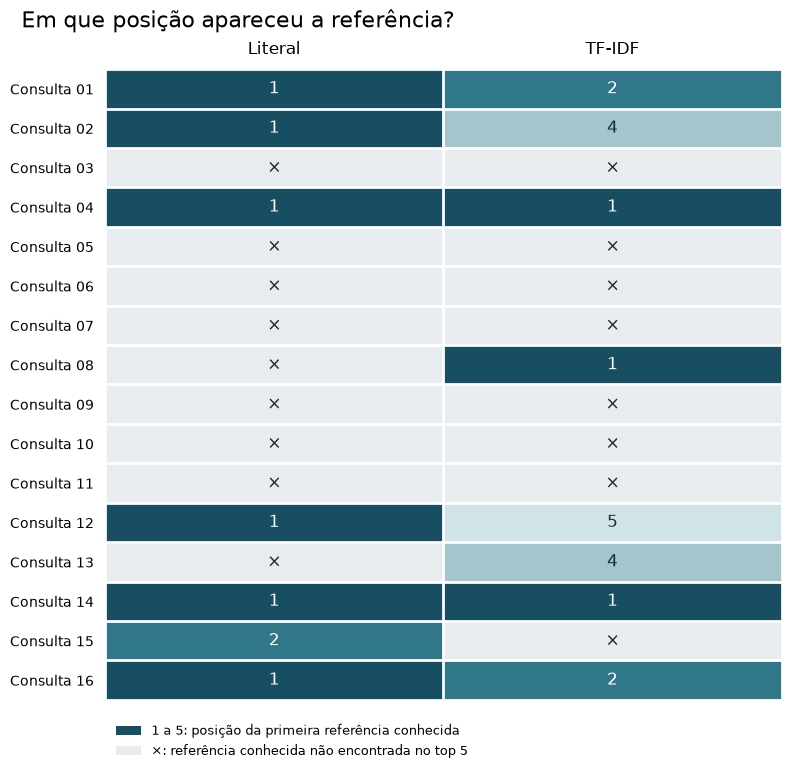

Gráfico adicional em figures/query_positions.png e figures/query_positions.svg


In [ ]:
"""Visualize known-reference positions from saved results, without running search."""


def query_positions(report, methods):
    rows = [row for row in report['results'] if row['answerable']]
    positions = [
        [next((rank for rank, hit in enumerate(row[key][:5], 1)
               if hit['id'] in row['known_relevant_ids']), 0)
         for key, _ in methods]
        for row in rows
    ]
    return [row['id'] for row in rows], positions


def plot_positions(report, methods):
    import matplotlib.pyplot as plt
    from matplotlib.colors import BoundaryNorm, ListedColormap
    from matplotlib.patches import Patch

    ids, positions = query_positions(report, methods)
    if not ids:
        raise ValueError('No positive queries in saved report.')
    colors = ['#E9ECEF', '#184E62', '#31778A', '#6AA2AD', '#A3C5CB', '#D0E3E6']
    cmap = ListedColormap(colors)
    fig, ax = plt.subplots(figsize=(7.8, max(6, len(ids) * .37 + 1.7)), layout='constrained')
    ax.imshow(positions, cmap=cmap, norm=BoundaryNorm([-.5, .5, 1.5, 2.5, 3.5, 4.5, 5.5], cmap.N), aspect='auto')
    ax.set_xticks(range(len(methods)), [name for _, name in methods], fontsize=12)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(ids)), [f'Consulta {name.rsplit("-", 1)[-1]}' for name in ids])
    ax.tick_params(length=0, pad=8)
    for row, values in enumerate(positions):
        for column, rank in enumerate(values):
            ax.text(column, row, str(rank) if rank else '×', ha='center', va='center',
                    fontsize=12, color='white' if rank in (1, 2) else '#172B3A')
    ax.set_xticks([index - .5 for index in range(len(methods) + 1)], minor=True)
    ax.set_yticks([index - .5 for index in range(len(ids) + 1)], minor=True)
    ax.grid(which='minor', color='white', linewidth=2)
    ax.tick_params(which='minor', length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.suptitle('Em que posição apareceu a referência?', fontsize=16, x=.02, ha='left')
    ax.legend(handles=[Patch(facecolor=colors[1], label='1 a 5: posição da primeira referência conhecida'),
                       Patch(facecolor=colors[0], label='×: referência conhecida não encontrada no top 5')],
              loc='upper left', bbox_to_anchor=(0, -.02), frameon=False, fontsize=9)
    return fig


fig = plot_positions(report, [('literal', 'Literal'), ('tfidf', 'TF-IDF')])
export_figure(fig, "query_positions")
print("Gráfico adicional em figures/query_positions.png e figures/query_positions.svg")


## 5. Aplicação prática e limites

Uma ferramenta de busca documental precisa permitir que a pessoa confira o trecho e sua fonte. Este experimento mostra que encontrar mais referências conhecidas pode vir junto com retornos enganosos quando a pergunta não tem resposta. Para avaliar métodos semelhantes em um projeto de cliente, seria preciso usar consultas e documentos representativos daquele contexto.

O conjunto é pequeno, as quatro consultas negativas são anacrônicas (incluem elementos de outra época) e as referências positivas são limitadas. As taxas descrevem somente as consultas anotadas; não são uma medida geral de acurácia. Qualquer regra nova para deixar de responder precisaria de outro ciclo de desenvolvimento e de um novo teste independente. Nenhum parâmetro foi alterado com base nos resultados finais.

Fonte e créditos: os arquivos TXT anexados pelo dataset identificam Arthur Conan Doyle e edições do Project Gutenberg. Os arquivos originais mantêm seus avisos e créditos. Este notebook apresenta contagens, consultas e identificadores de linhas, sem republicar o texto das obras.

## 6. Arquivos para download e reprodução

O JSON reúne resultados de cada consulta, scores, identificadores de origem, contagens do acervo e versões. Os gráficos são exportados em PNG e SVG. Depois de salvar uma versão executada, baixe esses arquivos na área **Output** do Kaggle.

In [8]:
table(["Componente do processamento", "Versão"], list(report["versions"].items()))
print("Saídas em:", "sherlock_analysis/search_results.json e sherlock_analysis/figures/")
table(["Arquivo", "Formato"], [(REPORT_PATH.name, "JSON")] +
      [("figures/" + path.name, path.suffix[1:].upper()) for path in sorted(FIGURE_DIR.glob("*"))])


| Componente do processamento | Versão |
| --- | --- |
| python | 3.11.17 |
| scikit-learn | 1.9.1 |
| numpy | 2.4.6 |
| scipy | 1.17.1 |

Saídas em: sherlock_analysis/search_results.json e sherlock_analysis/figures/


| Arquivo | Formato |
| --- | --- |
| search_results.json | JSON |
| figures/corpus_size.png | PNG |
| figures/corpus_size.svg | SVG |
| figures/retrieval_comparison.png | PNG |
| figures/retrieval_comparison.svg | SVG |